# COMP813 — Notebook 09: Robustness Analysis

**Purpose:** Evaluate how the three trained models respond to controlled changes in CEAS-08 email text without retraining or fine-tuning.

The experiment measures robustness under:

1. **Clean text** — original CEAS-08 input.
2. **Punctuation removal** — punctuation characters are removed while word content is retained.
3. **5% token deletion** — a fixed random seed removes approximately 5% of tokens.
4. **10% token deletion** — a fixed random seed removes approximately 10% of tokens.

The same perturbations are applied to the same emails for all models. Performance is compared with the clean baseline.

This is a controlled robustness experiment, not a claim that these perturbations reproduce a specific real-world attack.

**Model architecture note:** The BiLSTM checkpoint used in this project contains a **1-layer bidirectional LSTM**. The robustness notebook recreates that saved architecture exactly rather than retraining or changing the model.


In [1]:
import os
import re
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

from torch.utils.data import DataLoader, TensorDataset
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

SEED = 813
rng = np.random.default_rng(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

Device: cpu


In [2]:
# Load CEAS-08
ceas_df = pd.read_csv("ceas08_clean.csv")
X_ceas = ceas_df["text"].astype(str)
y_ceas = ceas_df["label"].to_numpy()

print("CEAS-08 size:", len(ceas_df))

CEAS-08 size: 38964


In [3]:
# Load classical models and vectorizers
lr_model = joblib.load("../models/logistic_regression_enron.pkl")
lr_tfidf = joblib.load("../models/tfidf_vectorizer.pkl")

svm_model = joblib.load("../models/svm_enron.pkl")
svm_tfidf = joblib.load("../models/tfidf_svm_vectorizer.pkl")

print("Classical models loaded.")

Classical models loaded.


In [4]:
# Load BiLSTM vocabulary and checkpoint
with open("../models/bilstm_vocabulary.json", "r", encoding="utf-8") as f:
    vocab = json.load(f)

checkpoint = torch.load(
    "../models/bilstm_enron.pt",
    map_location=device
)

class BiLSTMClassifier(nn.Module):
    def __init__(self, vocab_size, embedding_dim, hidden_dim, dropout):
        super().__init__()

        self.embedding = nn.Embedding(
            vocab_size,
            embedding_dim,
            padding_idx=0
        )

        self.lstm = nn.LSTM(
            input_size=embedding_dim,
            hidden_size=hidden_dim,
            num_layers=1,
            batch_first=True,
            bidirectional=True
        )

        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(hidden_dim * 2, 1)

    def forward(self, x):
        embedded = self.embedding(x)
        output, (hidden, cell) = self.lstm(embedded)

        forward_hidden = hidden[-2]
        backward_hidden = hidden[-1]

        combined_hidden = torch.cat(
            (forward_hidden, backward_hidden),
            dim=1
        )

        combined_hidden = self.dropout(combined_hidden)
        output = self.fc(combined_hidden)

        return output.squeeze(1)


bilstm_model = BiLSTMClassifier(
    vocab_size=checkpoint["vocab_size"],
    embedding_dim=checkpoint["embedding_dim"],
    hidden_dim=checkpoint["hidden_dim"],
    dropout=checkpoint["dropout"]
)

bilstm_model.load_state_dict(checkpoint["model_state_dict"])
bilstm_model.to(device)
bilstm_model.eval()

max_length = checkpoint["max_sequence_length"]

print("BiLSTM loaded.")
print("Maximum sequence length:", max_length)

BiLSTM loaded.
Maximum sequence length: 500


## Perturbation functions

The token-deletion perturbations use deterministic per-email seeds so that the experiment is reproducible. Tokens are deleted from the original token sequence; no new information is introduced.

In [5]:
def tokenize_text(text):
    return re.findall(r"\b\w+\b", text.lower())


def remove_punctuation(text):
    text = re.sub(r"[^\w\s]", " ", text)
    text = re.sub(r"\s+", " ", text)
    return text.strip()


def delete_tokens(text, deletion_rate, seed):
    tokens = text.split()

    if len(tokens) <= 1:
        return text

    local_rng = np.random.default_rng(seed)
    keep_mask = local_rng.random(len(tokens)) >= deletion_rate

    # Ensure at least one token remains
    if not keep_mask.any():
        keep_mask[local_rng.integers(0, len(tokens))] = True

    return " ".join(
        token for token, keep in zip(tokens, keep_mask)
        if keep
    )

In [6]:
# Create the four evaluation conditions
perturbations = {
    "Clean": X_ceas.copy(),
    "Punctuation Removed": X_ceas.apply(remove_punctuation),
    "5% Token Deletion": pd.Series(
        [
            delete_tokens(text, 0.05, SEED + i)
            for i, text in enumerate(X_ceas)
        ],
        index=X_ceas.index
    ),
    "10% Token Deletion": pd.Series(
        [
            delete_tokens(text, 0.10, SEED + 100000 + i)
            for i, text in enumerate(X_ceas)
        ],
        index=X_ceas.index
    )
}

for name, texts in perturbations.items():
    print(
        f"{name}: "
        f"mean characters = {texts.str.len().mean():.1f}"
    )

Clean: mean characters = 1558.8
Punctuation Removed: mean characters = 1431.6
5% Token Deletion: mean characters = 1480.9
10% Token Deletion: mean characters = 1402.9


In [7]:
def classical_predict(texts, model, vectorizer):
    X = vectorizer.transform(texts)
    return model.predict(X)


def text_to_sequence(text, max_length):
    tokens = tokenize_text(text)

    sequence = [
        vocab.get(token, vocab.get("<UNK>", 1))
        for token in tokens[:max_length]
    ]

    if len(sequence) < max_length:
        sequence += [
            vocab.get("<PAD>", 0)
        ] * (max_length - len(sequence))

    return sequence


def bilstm_predict(texts, batch_size=256):
    sequences = np.array(
        [
            text_to_sequence(text, max_length)
            for text in texts
        ],
        dtype=np.int64
    )

    tensor_x = torch.tensor(
        sequences,
        dtype=torch.long
    )

    loader = DataLoader(
        TensorDataset(tensor_x),
        batch_size=batch_size,
        shuffle=False
    )

    predictions = []

    with torch.no_grad():
        for (batch_x,) in loader:
            batch_x = batch_x.to(device)
            logits = bilstm_model(batch_x)

            batch_predictions = (
                torch.sigmoid(logits) >= 0.5
            ).long()

            predictions.extend(
                batch_predictions.cpu().numpy()
            )

    return np.array(predictions)

In [8]:
# Run robustness evaluation
robustness_rows = []
predictions_store = {}

for condition, texts in perturbations.items():
    print(f"\nRunning: {condition}")

    lr_pred = classical_predict(
        texts,
        lr_model,
        lr_tfidf
    )

    svm_pred = classical_predict(
        texts,
        svm_model,
        svm_tfidf
    )

    bilstm_pred = bilstm_predict(texts)

    predictions_store[condition] = {
        "lr": lr_pred,
        "svm": svm_pred,
        "bilstm": bilstm_pred
    }

    for model_name, predictions in [
        ("Logistic Regression", lr_pred),
        ("Linear SVM", svm_pred),
        ("BiLSTM", bilstm_pred)
    ]:
        tn, fp, fn, tp = confusion_matrix(
            y_ceas,
            predictions,
            labels=[0, 1]
        ).ravel()

        robustness_rows.append({
            "condition": condition,
            "model": model_name,
            "accuracy": accuracy_score(y_ceas, predictions),
            "precision": precision_score(
                y_ceas, predictions, zero_division=0
            ),
            "recall": recall_score(
                y_ceas, predictions, zero_division=0
            ),
            "f1": f1_score(
                y_ceas, predictions, zero_division=0
            ),
            "false_positives": fp,
            "false_negatives": fn
        })

robustness_df = pd.DataFrame(robustness_rows)
robustness_df


Running: Clean

Running: Punctuation Removed

Running: 5% Token Deletion

Running: 10% Token Deletion


,condition,model,accuracy,precision,recall,f1,false_positives,false_negatives
0,Clean,Logistic Regression,0.667437,0.626187,0.997785,0.769472,12910,48
1,Clean,Linear SVM,0.687737,0.641267,0.995571,0.780073,12071,96
2,Clean,BiLSTM,0.565394,0.573284,0.855403,0.686489,13800,3134
3,Punctuation Removed,Logistic Regression,0.667437,0.626187,0.997785,0.769472,12910,48
4,Punctuation Removed,Linear SVM,0.687737,0.641267,0.995571,0.780073,12071,96
5,Punctuation Removed,BiLSTM,0.565394,0.573284,0.855403,0.686489,13800,3134
6,5% Token Deletion,Logistic Regression,0.666487,0.625561,0.997509,0.768916,12941,54
7,5% Token Deletion,Linear SVM,0.686480,0.640393,0.995248,0.779327,12113,103
8,5% Token Deletion,BiLSTM,0.593086,0.587307,0.903017,0.711722,13753,2102
9,10% Token Deletion,Logistic Regression,0.664383,0.624080,0.997509,0.767797,13023,54


In [9]:
# Calculate F1 degradation relative to each model's clean baseline
clean_f1 = (
    robustness_df[
        robustness_df["condition"] == "Clean"
    ][["model", "f1"]]
    .rename(columns={"f1": "clean_f1"})
)

robustness_df = robustness_df.merge(
    clean_f1,
    on="model",
    how="left"
)

robustness_df["f1_change_pp"] = (
    robustness_df["f1"] - robustness_df["clean_f1"]
) * 100

robustness_df["f1_degradation_pp"] = (
    robustness_df["clean_f1"] - robustness_df["f1"]
) * 100

robustness_df[
    [
        "condition",
        "model",
        "f1",
        "f1_change_pp",
        "f1_degradation_pp"
    ]
]

,condition,model,f1,f1_change_pp,f1_degradation_pp
0,Clean,Logistic Regression,0.769472,0.000000,0.000000
1,Clean,Linear SVM,0.780073,0.000000,0.000000
2,Clean,BiLSTM,0.686489,0.000000,0.000000
3,Punctuation Removed,Logistic Regression,0.769472,0.000000,0.000000
4,Punctuation Removed,Linear SVM,0.780073,0.000000,0.000000
5,Punctuation Removed,BiLSTM,0.686489,0.000000,0.000000
6,5% Token Deletion,Logistic Regression,0.768916,-0.055547,0.055547
7,5% Token Deletion,Linear SVM,0.779327,-0.074610,0.074610
8,5% Token Deletion,BiLSTM,0.711722,2.523334,-2.523334
9,10% Token Deletion,Logistic Regression,0.767797,-0.167504,0.167504


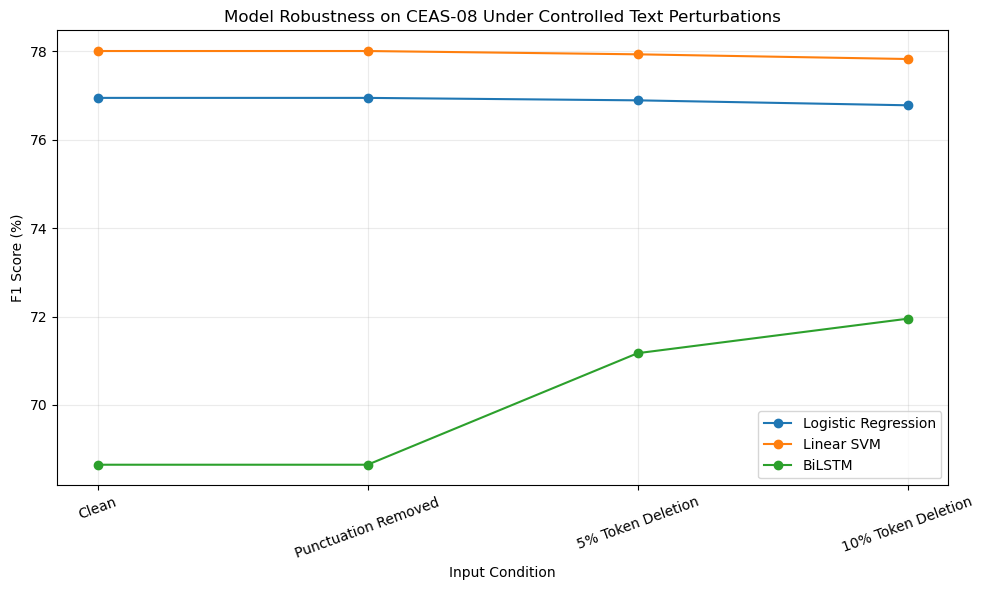

In [10]:
# Plot F1 under perturbations
plt.figure(figsize=(10, 6))

for model_name in [
    "Logistic Regression",
    "Linear SVM",
    "BiLSTM"
]:
    subset = robustness_df[
        robustness_df["model"] == model_name
    ]

    plt.plot(
        subset["condition"],
        subset["f1"] * 100,
        marker="o",
        label=model_name
    )

plt.ylabel("F1 Score (%)")
plt.xlabel("Input Condition")
plt.title("Model Robustness on CEAS-08 Under Controlled Text Perturbations")
plt.xticks(rotation=20)
plt.grid(True, alpha=0.25)
plt.legend()
plt.tight_layout()
plt.show()

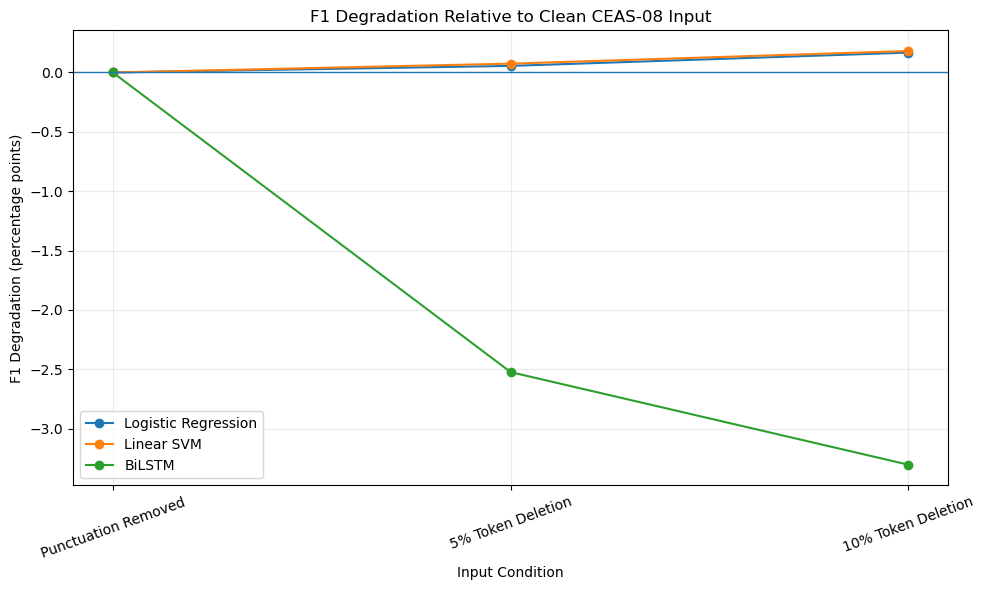

In [11]:
# Plot F1 degradation relative to clean input
degradation_plot = robustness_df[
    robustness_df["condition"] != "Clean"
].copy()

plt.figure(figsize=(10, 6))

for model_name in [
    "Logistic Regression",
    "Linear SVM",
    "BiLSTM"
]:
    subset = degradation_plot[
        degradation_plot["model"] == model_name
    ]

    plt.plot(
        subset["condition"],
        subset["f1_degradation_pp"],
        marker="o",
        label=model_name
    )

plt.axhline(0, linewidth=1)
plt.ylabel("F1 Degradation (percentage points)")
plt.xlabel("Input Condition")
plt.title("F1 Degradation Relative to Clean CEAS-08 Input")
plt.xticks(rotation=20)
plt.grid(True, alpha=0.25)
plt.legend()
plt.tight_layout()
plt.show()

## Prediction stability

Performance degradation is only one aspect of robustness. The next table measures how many individual predictions change under each perturbation relative to the clean input.

In [12]:
stability_rows = []

for condition in perturbations:
    if condition == "Clean":
        continue

    for model_name, key in [
        ("Logistic Regression", "lr"),
        ("Linear SVM", "svm"),
        ("BiLSTM", "bilstm")
    ]:
        changed = (
            predictions_store[condition][key]
            != predictions_store["Clean"][key]
        )

        stability_rows.append({
            "condition": condition,
            "model": model_name,
            "changed_predictions": int(changed.sum()),
            "prediction_change_rate": changed.mean()
        })

stability_df = pd.DataFrame(stability_rows)
stability_df

,condition,model,changed_predictions,prediction_change_rate
0,Punctuation Removed,Logistic Regression,0,0.000000
1,Punctuation Removed,Linear SVM,0,0.000000
2,Punctuation Removed,BiLSTM,0,0.000000
3,5% Token Deletion,Logistic Regression,479,0.012293
4,5% Token Deletion,Linear SVM,617,0.015835
5,5% Token Deletion,BiLSTM,2005,0.051458
6,10% Token Deletion,Logistic Regression,771,0.019787
7,10% Token Deletion,Linear SVM,976,0.025049
8,10% Token Deletion,BiLSTM,2825,0.072503


In [13]:
# Save robustness results
os.makedirs("../results", exist_ok=True)

robustness_df.to_csv(
    "../results/robustness_analysis_results.csv",
    index=False
)

stability_df.to_csv(
    "../results/robustness_prediction_stability.csv",
    index=False
)

print("Saved:")
print("../results/robustness_analysis_results.csv")
print("../results/robustness_prediction_stability.csv")

Saved:
../results/robustness_analysis_results.csv
../results/robustness_prediction_stability.csv


## Interpretation guide

Use the results to answer three questions:

1. **Performance robustness:** Which models retain their F1 score when text is perturbed?
2. **Error sensitivity:** Do false positives or false negatives increase disproportionately under a perturbation?
3. **Prediction stability:** How frequently do individual decisions change relative to clean input?

The perturbations are deliberately controlled and synthetic. They should therefore be described as **robustness probes**, not as realistic attacks or a complete robustness assessment.

If a model's F1 changes only slightly while individual predictions change more often, report both findings: aggregate performance can remain stable even when individual decisions are sensitive.